# Stage 3. Preprocessing and quality control

This notebook uses Group 10's expression and metadata exports for [GEO GSE15852](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE15852), an Affymetrix GPL96 breast tumour and patient-matched normal tissue study. The acquisition notebook maps probe sets to source gene symbols and keeps the first listed annotation where a probe has multiple symbols. Probe IDs are absent from the supplied matrix. The values are processed signal intensities. A raw-count export is inapplicable.

Run from the repository root or its notebooks folder. In Colab, upload both supplied CSVs to the session working directory or place the paired exports under `data/` using Stage 2. The code also recognizes the local nested expression file. Keep both input files from the same acquisition run. Saved evidence is written to `data/person2/`.

In [1]:
from collections import Counter
import csv
import gzip
import hashlib
from pathlib import Path

from IPython.display import Image, display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent

input_pairs = [
    (root / "expression_matrix.csv" / "expression_matrix.csv", root / "metadata.csv"),
    (root / "expression_matrix.csv", root / "metadata.csv"),
    (root / "data" / "expression_matrix.csv", root / "data" / "metadata.csv"),
    (root / "data" / "expression_matrix.csv.gz", root / "data" / "metadata.csv"),
]
inputs = next((pair for pair in input_pairs if all(path.is_file() for path in pair)), None)
if inputs is None:
    raise FileNotFoundError("Place the expression matrix and metadata together as described above.")
expression_file, metadata_file = inputs
output_dir = root / "data" / "person2"

def read_csv_checked(path):
    opener = gzip.open if path.suffix == ".gz" else open
    with opener(path, mode="rt", encoding="utf-8-sig", newline="") as source:
        header = next(csv.reader(source))
    duplicates = [name for name, count in Counter(header).items() if count > 1]
    if duplicates:
        raise ValueError(f"Duplicate columns in {path.name}: {duplicates}")
    return pd.read_csv(path, dtype=str, keep_default_na=False)

raw = read_csv_checked(expression_file)
metadata = read_csv_checked(metadata_file)
for path in inputs:
    print(f"{path.relative_to(root)} | SHA-256 {hashlib.sha256(path.read_bytes()).hexdigest()}")

expression_matrix.csv\expression_matrix.csv | SHA-256 6295541cf01673a05cd06d7ae7344e25b6b52f6d41c3bd8eef52fa940b111dde
metadata.csv | SHA-256 a8f949a4bac6efc6b81b74a491989b1585535e511c60ca85da00d40d05220556


## Sample and expression checks

The expression header defines sample order. We require a one-to-one match to metadata, validate the tissue labels and verify that each patient contributes exactly one sample per class. Invalid values or mismatched IDs stop the run for review. This avoids hidden sample losses or imputation.

In [2]:
required = ["sample_id", "sample_title", "patient_id", "condition", "label", "source_tissue"]
if not set(required).issubset(metadata) or raw.columns[0] != "Gene_Symbol":
    raise ValueError("Required metadata fields or Gene_Symbol header are missing.")

metadata = metadata.apply(lambda col: col.str.strip())
sample_ids = pd.Index(raw.columns[1:], name="sample_id")
metadata_missing = int(metadata[required].eq("").sum().sum())
metadata_duplicates = int(metadata["sample_id"].duplicated().sum())
if metadata_missing or metadata_duplicates:
    raise ValueError(f"Metadata has {metadata_missing} blank required cells and {metadata_duplicates} duplicate IDs.")

expression_only = sample_ids.difference(metadata["sample_id"])
metadata_only = pd.Index(metadata["sample_id"]).difference(sample_ids)
if len(expression_only) or len(metadata_only):
    raise ValueError(f"Unmatched IDs: expression={list(expression_only)}, metadata={list(metadata_only)}")
metadata = metadata.set_index("sample_id").loc[sample_ids]
if not metadata["condition"].map({"Normal": "0", "Tumor": "1"}).eq(metadata["label"]).all():
    raise ValueError("Condition and binary label disagree.")
expected_title = metadata["condition"].map({"Normal": "normal", "Tumor": "cancer"})
expected_id = "Patient_" + metadata["sample_title"].str.extract(r"(?i)BC(\d+)[NT]$", expand=False)
expected_suffix = metadata["condition"].map({"Normal": "N", "Tumor": "T"})
if not (metadata["sample_title"].str.split().str[0].str.lower().eq(expected_title)
        & metadata["sample_title"].str[-1].eq(expected_suffix)
        & metadata["patient_id"].eq(expected_id)).all():
    raise ValueError("Metadata conditions or patient IDs disagree with the sample titles.")
pair_table = pd.crosstab(metadata["patient_id"], metadata["condition"]).reindex(
    columns=["Normal", "Tumor"], fill_value=0
)
if not pair_table.eq(1).all().all():
    raise ValueError("Expected one Normal and one Tumor sample per patient.")

symbols = raw["Gene_Symbol"].str.strip()
valid_symbol = ~symbols.str.upper().isin(["", "---", "NA", "N/A", "NULL", "NAN"])
input_values = raw.iloc[:, 1:].apply(lambda col: col.str.strip())
missing_mask = input_values.isin(["", "NA", "N/A", "NaN", "nan", "null", "NULL"])
values = input_values.mask(missing_mask).apply(pd.to_numeric, errors="coerce")
missing_count = int(missing_mask.sum().sum())
nonnumeric_count = int((values.isna() & ~missing_mask).sum().sum())
infinite_count = int(np.isinf(values.to_numpy()).sum())
negative_count = int(values.lt(0).sum().sum())
if any((missing_count, nonnumeric_count, infinite_count, negative_count)):
    raise ValueError(f"Review missing={missing_count}, nonnumeric={nonnumeric_count}, "
                     f"infinite={infinite_count}, negative={negative_count} expression cells.")

values.index = pd.Index(symbols, name="Gene_Symbol")
exact_rows = int(values.reset_index().duplicated().sum())
duplicate_profiles = int(values.T.duplicated().sum())
print(f"Matched samples: {len(sample_ids)}. Complete patient pairs: {len(pair_table)}.")
print(metadata["condition"].value_counts().to_string())
print(f"Input intensities range from {values.min().min():.4g} to {values.max().max():.4g}.")
print(f"Exact duplicate sample profiles: {duplicate_profiles}. Exact duplicate rows: {exact_rows}.")

Matched samples: 86. Complete patient pairs: 43.
condition
Normal    43
Tumor     43
Input intensities range from 0.4325 to 1.904e+04.
Exact duplicate sample profiles: 0. Exact duplicate rows: 0.


## Gene-level filtering and transformation

Remove rows with blank or placeholder symbols and drop exact duplicates with the same symbol and intensity profile. Combine the remaining rows sharing a symbol by their per-sample median on the supplied intensity scale. The median gives each source row equal weight and reduces sensitivity to extreme probe signals. It is a practical gene-level summary and can obscure probe-specific or isoform-specific differences. Retain the source symbol text, including legacy names, for downstream mapping.

Apply a zero-variance filter to remove genes that are constant across all 86 samples. Avoid an arbitrary low-intensity threshold because the input lacks probe detection calls. Then apply the fixed, element-wise transform `log2(intensity + 1)` to compress the right tail. No across-sample normalization or label-driven feature selection is fitted here. Use this logged matrix directly for EDA and exploratory paired microarray analysis. For ML, keep both samples from a patient in the same split and fit any further scaling or feature selection inside training folds.

In [3]:
valid_rows = values.loc[valid_symbol.to_numpy()]
distinct_rows = valid_rows.loc[~valid_rows.reset_index().duplicated().to_numpy()]
probe_counts = distinct_rows.groupby(level=0, sort=False).size()
gene_intensity = distinct_rows.groupby(level=0, sort=False).median()
constant = gene_intensity.nunique(axis=1).le(1)
kept = gene_intensity.loc[~constant]
clean_expression = np.log2(kept + 1)

row_action = np.full(len(raw), "retained_single_symbol_row", dtype=object)
row_action[~valid_symbol.to_numpy()] = "excluded_missing_symbol"
valid_positions = np.flatnonzero(valid_symbol.to_numpy())
exact_duplicate_mask = valid_rows.reset_index().duplicated().to_numpy()
row_action[valid_positions[exact_duplicate_mask]] = "excluded_exact_duplicate_row"
distinct_positions = valid_positions[~exact_duplicate_mask]
row_action[distinct_positions[distinct_rows.index.isin(probe_counts[probe_counts.gt(1)].index)]] = (
    "combined_by_symbol_median"
)
row_action[distinct_positions[distinct_rows.index.isin(constant[constant].index)]] = (
    "excluded_constant_gene"
)
row_record = pd.DataFrame({
    "input_csv_line": np.arange(2, len(raw) + 2),
    "Gene_Symbol": symbols,
    "action": row_action,
    "retained_gene_source_rows": symbols.map(probe_counts).astype("Int64"),
})

summary = pd.DataFrame([
    ("Expression rows (probe-derived rows before, unique genes after)", len(raw), len(clean_expression)),
    ("Distinct non-placeholder gene symbols", symbols[valid_symbol].nunique(), len(clean_expression)),
    ("Samples", len(sample_ids), clean_expression.shape[1]),
    ("Normal samples", int(metadata.condition.eq("Normal").sum()), int(metadata.condition.eq("Normal").sum())),
    ("Tumor samples", int(metadata.condition.eq("Tumor").sum()), int(metadata.condition.eq("Tumor").sum())),
    ("Complete patient pairs", len(pair_table), len(pair_table)),
    ("Missing expression cells", missing_count, int(clean_expression.isna().sum().sum())),
    ("Nonnumeric expression cells", nonnumeric_count, 0),
    ("Infinite or negative expression cells", infinite_count + negative_count, 0),
    ("Blank required metadata fields", metadata_missing, 0),
    ("Unmatched sample IDs across files", len(expression_only) + len(metadata_only), 0),
    ("Duplicate sample IDs", metadata_duplicates, 0),
    ("Exact duplicate sample profiles", duplicate_profiles, int(clean_expression.T.duplicated().sum())),
    ("Exact duplicate expression rows with the same symbol", exact_rows, 0),
    ("Extra valid rows with a repeated gene symbol", int(symbols[valid_symbol].duplicated().sum()), 0),
    ("Missing or placeholder gene symbols", int((~valid_symbol).sum()), 0),
], columns=["Check", "Before", "After"])
changes = pd.DataFrame([
    ("Exclude blank or placeholder gene symbols", len(values) - len(valid_rows)),
    ("Exclude exact duplicate rows (same symbol and all intensities)", len(valid_rows) - len(distinct_rows)),
    ("Collapse surplus rows by per-sample same-symbol median", len(distinct_rows) - len(gene_intensity)),
    ("Exclude constant gene-level rows", int(constant.sum())),
    ("Samples excluded", 0),
], columns=["Operation", "Rows_or_samples_affected"])
assert clean_expression.index.is_unique and clean_expression.columns.equals(metadata.index)
assert np.isfinite(clean_expression.to_numpy()).all()
assert len(clean_expression) == len(raw) - changes.loc[:3, "Rows_or_samples_affected"].sum()
display(summary, changes)

,Check,Before,After
0,"Expression rows (probe-derived rows before, un...",21225,13237
1,Distinct non-placeholder gene symbols,13237,13237
2,Samples,86,86
3,Normal samples,43,43
4,Tumor samples,43,43
5,Complete patient pairs,43,43
6,Missing expression cells,0,0
7,Nonnumeric expression cells,0,0
8,Infinite or negative expression cells,0,0
9,Blank required metadata fields,0,0


,Operation,Rows_or_samples_affected
0,Exclude blank or placeholder gene symbols,0
1,Exclude exact duplicate rows (same symbol and ...,0
2,Collapse surplus rows by per-sample same-symbo...,7988
3,Exclude constant gene-level rows,0
4,Samples excluded,0


## Sample quality screen

Compare sample median intensity on the supplied scale and median Spearman correlation to all other expression profiles. Flag medians outside the pooled 1.5×IQR fences or correlations below their lower fence. These are descriptive screens. A flagged sample can reflect biology or technical variation. Review the source and batch records before deciding on exclusion. Retain all pairs for this handover.

Median intensity fence: -79.47 to 1044.83
Lower correlation fence: 0.788
Flagged samples: 5. Samples excluded: 0.
Lowest median correlation: GSM398100 (0.676).


,patient_id,condition,median_input_intensity,median_log2_gene_expression,median_spearman_to_other_samples,intensity_flag,correlation_flag,review_flag
sample_id,,,,,,,,
GSM398074,Patient_0043,Normal,333.232,8.485238,0.775306,False,True,True
GSM398100,Patient_0147,Normal,376.186,8.619574,0.676328,False,True,True
GSM398123,Patient_0165,Tumor,320.767,8.440172,0.776082,False,True,True
GSM398154,Patient_0191,Normal,583.404,9.312713,0.768804,False,True,True
GSM398155,Patient_0191,Tumor,558.374,9.265395,0.758818,False,True,True


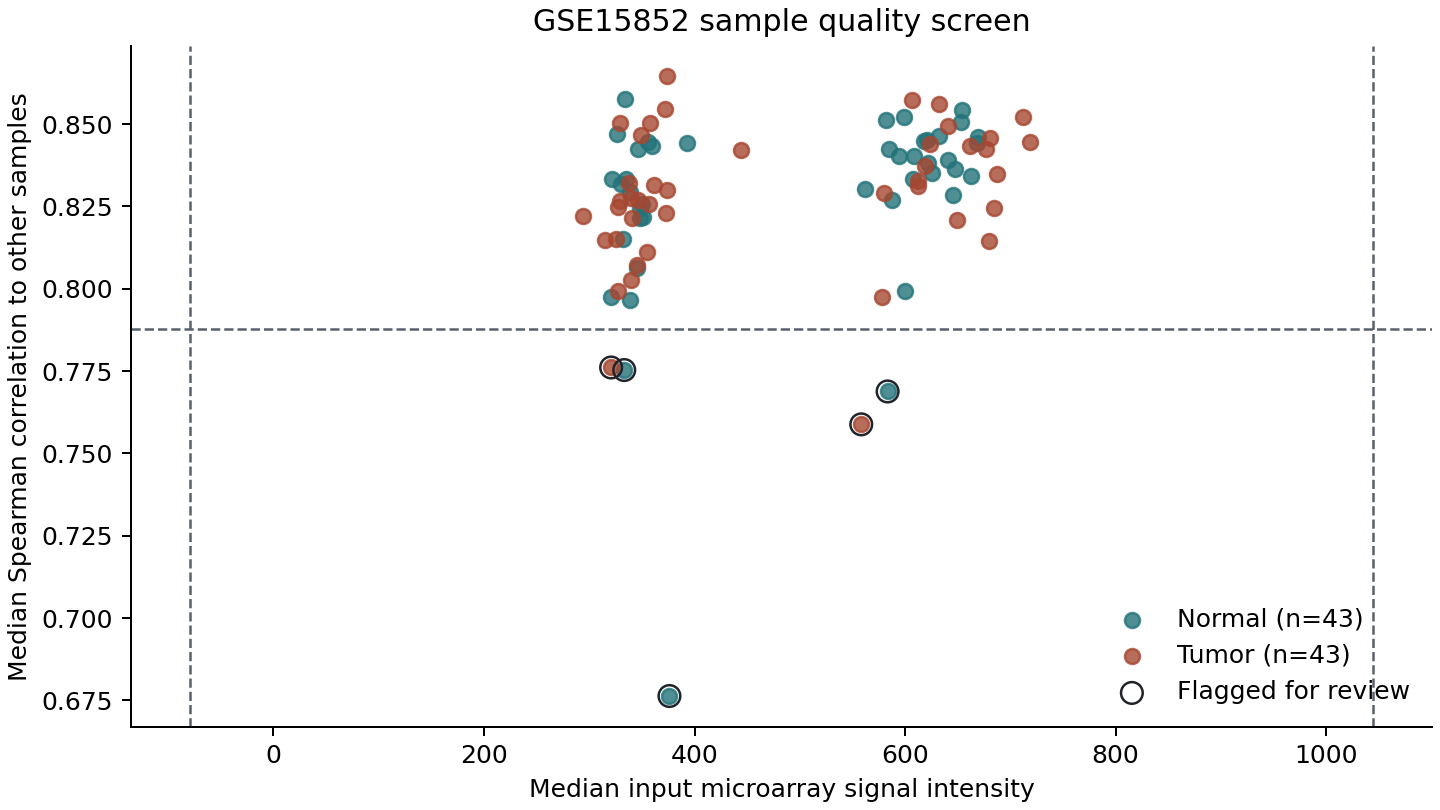

In [4]:
qc = metadata[["patient_id", "condition"]].copy()
qc["median_input_intensity"] = values.median(axis=0)
qc["median_log2_gene_expression"] = clean_expression.median(axis=0)
correlations = clean_expression.corr(method="spearman")
correlations = correlations.mask(np.eye(len(correlations), dtype=bool))
qc["median_spearman_to_other_samples"] = correlations.median(axis=0)

def iqr_fences(series):
    q1, q3 = series.quantile([0.25, 0.75])
    return q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)

intensity_low, intensity_high = iqr_fences(qc["median_input_intensity"])
correlation_low, _ = iqr_fences(qc["median_spearman_to_other_samples"])
qc["intensity_flag"] = ~qc["median_input_intensity"].between(intensity_low, intensity_high)
qc["correlation_flag"] = qc["median_spearman_to_other_samples"].lt(correlation_low)
qc["review_flag"] = qc["intensity_flag"] | qc["correlation_flag"]
print(f"Median intensity fence: {intensity_low:.2f} to {intensity_high:.2f}")
print(f"Lower correlation fence: {correlation_low:.3f}")
print(f"Flagged samples: {int(qc.review_flag.sum())}. Samples excluded: 0.")
lowest = qc["median_spearman_to_other_samples"].idxmin()
print(f"Lowest median correlation: {lowest} ({qc.at[lowest, 'median_spearman_to_other_samples']:.3f}).")
display(qc.loc[qc.review_flag])

fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
for label, color in [("Normal", "#23737A"), ("Tumor", "#A64731")]:
    group = qc.loc[qc.condition.eq(label)]
    ax.scatter(group["median_input_intensity"], group["median_spearman_to_other_samples"],
               label=f"{label} (n={len(group)})", color=color, alpha=.8)
ax.axhline(correlation_low, linestyle="--", color="#58616B", linewidth=1)
for threshold in [intensity_low, intensity_high]:
    ax.axvline(threshold, linestyle="--", color="#58616B", linewidth=1)
flagged = qc.loc[qc.review_flag]
ax.scatter(flagged["median_input_intensity"], flagged["median_spearman_to_other_samples"],
           facecolors="none", edgecolors="#21252B", s=75, label="Flagged for review")
ax.set(title="GSE15852 sample quality screen",
       xlabel="Median input microarray signal intensity",
       ylabel="Median Spearman correlation to other samples")
ax.legend(loc="lower right", frameon=False)
ax.spines[["right", "top"]].set_visible(False)

output_dir.mkdir(parents=True, exist_ok=True)
figure_path = output_dir / "sample_qc.png"
fig.savefig(figure_path, dpi=180, facecolor="white")
plt.close(fig)
display(Image(filename=str(figure_path), width=760))

## Handover files and interpretation

The clean expression CSV has one row per source gene symbol and one column per GEO sample accession. The clean metadata follows exactly the same sample order and preserves patient, condition and label. The two QC tables record before/after counts and the effect of each rule. The row audit identifies the input CSV line and its action. The sample QC CSV records the screening metrics and flags for every sample.

Flagged observations remain in the data. The processed expression preview cannot establish chip-level quality or distinguish batch effects from tissue biology. A paired sensitivity analysis can help assess whether flagged samples influence downstream conclusions.

In [5]:
clean_expression.to_csv(output_dir / "clean_expression.csv", float_format="%.12g")
metadata.to_csv(output_dir / "clean_metadata.csv")
summary.to_csv(output_dir / "qc_before_after.csv", index=False)
changes.to_csv(output_dir / "qc_changes.csv", index=False)
row_record.to_csv(output_dir / "gene_row_audit.csv", index=False)
qc.to_csv(output_dir / "sample_qc.csv")
print(f"Saved {len(clean_expression):,} unique genes across {len(sample_ids)} samples "
      f"and {len(pair_table)} complete pairs in {output_dir.relative_to(root)}.")

Saved 13,237 unique genes across 86 samples and 43 complete pairs in data\person2.
